# Run previous notebook

In [316]:
# %run 01_eda_freight.ipynb

In [317]:
# from IPython.utils.capture import capture_output

# with capture_output():
#     get_ipython().run_line_magic('run', '01_eda_freight.ipynb')

In [318]:
# %pip install phik

In [319]:
# Imports
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.dates as mdates
from matplotlib.colors import LinearSegmentedColormap
# import phik
# import holidays

# Paths
DATA_DIR = Path("..") / "data"
CHARTS_DIR = Path("..") / "charts"
CHARTS_DIR.mkdir(parents=True, exist_ok=True)

In [320]:
# Rhine Freight Data
df_freight = pd.read_csv(DATA_DIR / "RhineFreightData.csv", sep=";")
df_freight['Date'] = pd.to_datetime(df_freight['Date'], dayfirst=True) 
# Drop empty rows
df_freight = df_freight.dropna(how="all")

# Weather Data
df_weather = pd.read_csv(DATA_DIR / "WeatherDataBasel.csv", sep=";")
df_weather['date'] = pd.to_datetime(df_weather['date'], dayfirst=True) # dates are dd/mm/yyyy
# Drop empty rows
df_weather = df_weather.dropna(how="all")
df_weather.rename(columns={'date': 'Date'}, inplace=True)

C:\Users\Leonor Fandinga\AppData\Local\Temp\ipykernel_23120\1432804113.py:12: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_weather.rename(columns={'date': 'Date'}, inplace=True)


In [321]:
df_complete = pd.merge(df_freight, df_weather, on='Date', how='left')

In [322]:
df_freight.shape, df_weather.shape, df_complete.shape

((1469, 8), (3652, 25), (1469, 32))

In [323]:
df_complete.head()

,Date,Freight,Mogas_Flat,Brent_flat,Diesel_Flat,Heating_Flat,Kaub_level,freight_ar,avg_uv_index,avgtemp,...,totalsnow,uv_index,visibility,weather_code,weather_descriptions,wind_degree,wind_dir,wind_speed,windchill,windgust
0,2013-01-03,44.55,573.622200,260.662494,572.019772,554.576878,430.0,NaN,1.0,2.0,...,0.0,1.0,10.0,122.0,['Overcast'],245.0,WSW,7.0,1.0,14.0
1,2013-01-04,41.55,577.435102,260.252075,574.219032,557.993052,389.0,NaN,1.0,4.0,...,0.0,1.0,0.0,248.0,['Fog'],283.0,WNW,6.0,3.0,12.0
2,2013-01-07,41.55,576.174887,258.999923,578.355303,561.713421,327.0,NaN,1.0,1.0,...,0.0,1.0,10.0,113.0,['Clear'],105.0,ESE,5.0,-2.0,10.0
3,2013-01-08,40.05,577.156585,259.078404,579.239037,562.503444,329.0,NaN,1.0,0.0,...,0.0,1.0,10.0,113.0,['Clear'],210.0,SSW,4.0,0.0,8.0
4,2013-01-09,38.55,578.066208,259.375000,583.323044,567.144726,320.0,NaN,1.0,-1.0,...,0.0,1.0,5.0,143.0,['Mist'],273.0,W,5.0,-3.0,10.0


In [324]:
df_complete.shape

(1469, 32)

In [325]:
df_complete.drop(columns=['avg_uv_index', 'uv_index', "weather_code", "wind_dir"], inplace=True)

C:\Users\Leonor Fandinga\AppData\Local\Temp\ipykernel_23120\3426618150.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_complete.drop(columns=['avg_uv_index', 'uv_index', "weather_code", "wind_dir"], inplace=True)


In [326]:
df_complete.dropna(subset=['Freight'], inplace=True)
# Price 5 rows ahead (the last 5 rows get NaN because they have no future)
df_complete['Freight_5days'] = df_complete['Freight'].shift(-5)
# Drop those last 5 rows
df_complete = df_complete.dropna(subset=['Freight_5days']).reset_index(drop=True)


C:\Users\Leonor Fandinga\AppData\Local\Temp\ipykernel_23120\2417152807.py:1: Pandas4Warning: The inplace keyword in DataFrame.dropna is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_complete.dropna(subset=['Freight'], inplace=True)


# 1. Baseline Model

In [327]:
col = 'Freight'

# Garante a ordem temporal (se tiveres uma coluna Date)
df_sorted = df_complete.sort_values('Date').reset_index(drop=True)
y = df_sorted[col]

# 1) Maior amplitude em 5 linhas seguidas (como antes)
amplitude = y.rolling(5).max() - y.rolling(5).min()
print('Maior amplitude em 5 linhas:', amplitude.max())

# 2) Previsão = média dos 5 dias anteriores (shift(1) exclui o próprio dia)
pred_mean5 = y.shift(1).rolling(5).mean()
erro_mean5 = (y - pred_mean5).abs()

# 3) Previsão = valor do dia anterior
pred_naive = y.shift(1)
erro_naive = (y - pred_naive).abs()

# Resultados
for nome, erro, pred in [('Média dos 5 dias anteriores', erro_mean5, pred_mean5),
                         ('Valor do dia anterior', erro_naive, pred_naive)]:
    i = erro.idxmax()
    print(f'\n{nome}')
    print('  Erro máximo:', round(erro[i], 2))
    print('  Erro médio (MAE):', round(erro.mean(), 2))
    print('  Valor real:', y[i], '| Previsão:', round(pred[i], 2))
    print('  Linha:', i)

Maior amplitude em 5 linhas: 224.39999999999998

Média dos 5 dias anteriores
  Erro máximo: 177.39
  Erro médio (MAE): 3.89
  Valor real: 151.35 | Previsão: 328.74
  Linha: 1438

Valor do dia anterior
  Erro máximo: 112.35
  Erro médio (MAE): 1.41
  Valor real: 248.1 | Previsão: 360.45
  Linha: 1437


In [328]:
# Previsões (usam só informação até ao dia t)
df_complete['pred_hoje']     = df_complete['Freight']
df_complete['pred_media5']   = df_complete['Freight'].rolling(5).mean()
# Hoje + variação dos últimos 5 dias = 2*y(t) - y(t-5)
df_complete['pred_momentum'] = df_complete['Freight'] + df_complete['Freight'].diff(5)

previsores = {
    'Preço de hoje': 'pred_hoje',
    'Média dos últimos 5 dias': 'pred_media5',
    'Hoje + variação 5 dias': 'pred_momentum',
}

# Mesmas linhas para os três métodos (media5 e momentum geram NaN nas primeiras linhas)
av = df_complete.dropna(subset=list(previsores.values()) + ['Freight_5days'])

def metricas(y_true, y_pred):
    erro = y_true - y_pred
    return {
        'MAE': erro.abs().mean(),
        'RMSE': np.sqrt((erro ** 2).mean()),
        'Erro máx': erro.abs().max(),
    }

# Todos os dias
resultados = pd.DataFrame({
    nome: metricas(av['Freight_5days'], av[col])
    for nome, col in previsores.items()
}).T

print(f'Nº de previsões avaliadas: {len(av)}')
display(resultados.round(2))

# Só dias extremos (top 10% do preço real a 5 dias)
extremo = av['Freight_5days'] >= av['Freight_5days'].quantile(0.90)

resultados_ext = pd.DataFrame({
    nome: metricas(av.loc[extremo, 'Freight_5days'], av.loc[extremo, col])
    for nome, col in previsores.items()
}).T

print('Dias extremos:')
display(resultados_ext.round(2))

Nº de previsões avaliadas: 1444


,MAE,RMSE,Erro máx
Preço de hoje,6.39,15.97,227.7
Média dos últimos 5 dias,8.47,19.44,214.2
Hoje + variação 5 dias,7.46,19.24,247.8


Dias extremos:


,MAE,RMSE,Erro máx
Preço de hoje,22.79,41.97,227.7
Média dos últimos 5 dias,26.96,44.07,214.2
Hoje + variação 5 dias,22.59,42.79,247.8


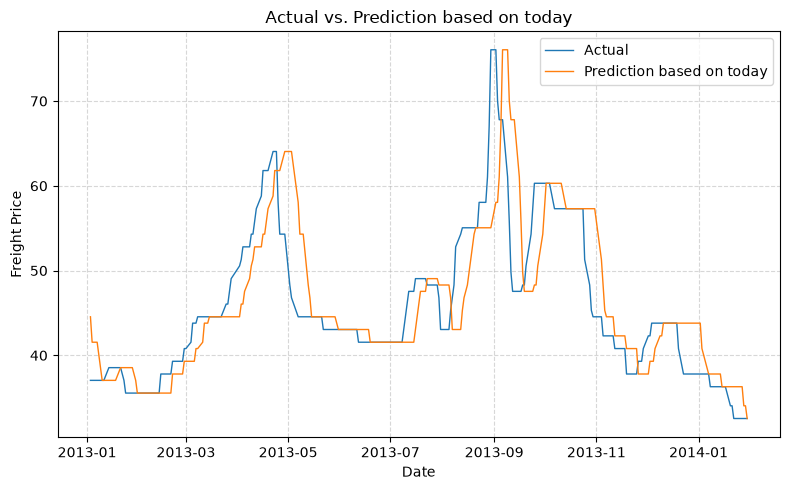

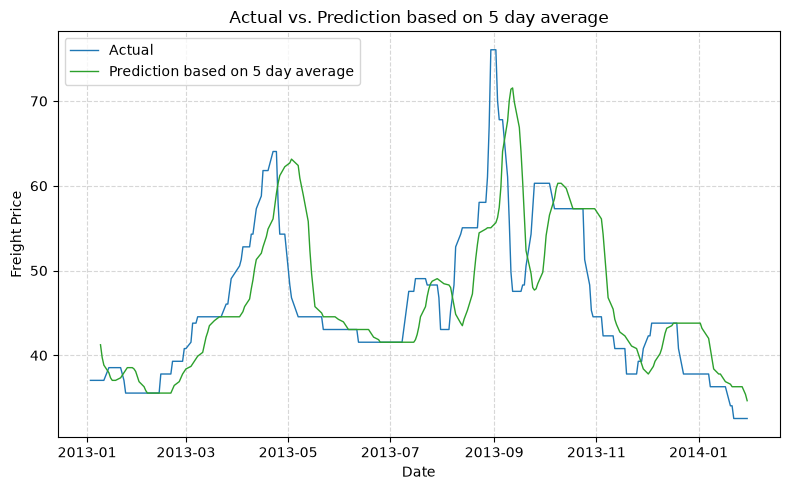

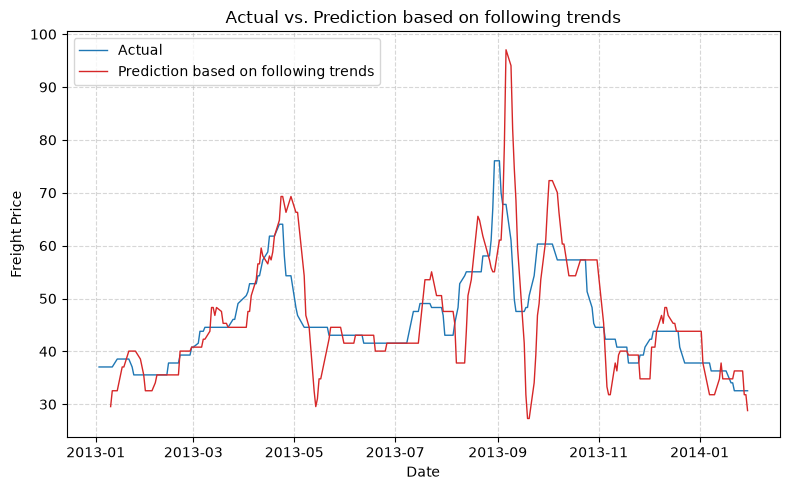

In [329]:
year = int(365 * 5 / 7)
subset = df_complete.iloc[:year]
x = subset['Date']

# Define (column_name, legend_label, line_color) for each baseline
baselines = [
    ('pred_hoje', 'Prediction based on today', '#ff7f0e'),
    ('pred_media5', 'Prediction based on 5 day average', '#2ca02c'),
    ('pred_momentum', 'Prediction based on following trends', '#d62728'),
]

for col, label, color in baselines:
    fig, ax = plt.subplots(figsize=(8, 5))
    
    ax.plot(x, subset['Freight_5days'], label='Actual', color='#1f77b4', linewidth=1)
    ax.plot(x, subset[col], label=label, color=color, linewidth=1)
    
    ax.set(title=f'Actual vs. {label}', xlabel='Date', ylabel='Freight Price')
    ax.grid(True, linestyle='--', alpha=0.5)
    ax.legend(loc='best')
    
    plt.tight_layout()

plt.show()

Cada hipotese de baseline tem vantagens e desvantagens. Pelos resultados a melhor baseline é assumir o preço de hoje para a previsao.
A media dos ultimos 5 dias tende  atrasar o sinal da trend na previsao piorando os resultados. 
A tentativa de seguir a tendencia (Hoje + variação) resulta em menores erros no inicio de tendencias mas erros amplificados quando o crescimento/diminuição de preço muda de sentido.

Por enquanto a baseline escolhida é o preço do proprio dia

# 2. Features

- Que features são mais importantes para o modelo?
- Que features são redundantes?
- Que tipo de split fazer? Cross-validation? Ter a certeza que nao existe data leakage
- Que modelos usar?
- Experimentar PCA para reduzir Weather features e gas price features?

Eliminar features claramente redundantes

In [330]:
df_complete.info()

<class 'pandas.DataFrame'>
RangeIndex: 1449 entries, 0 to 1448
Data columns (total 32 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   Date                  1449 non-null   datetime64[us]
 1   Freight               1449 non-null   float64       
 2   Mogas_Flat            1449 non-null   float64       
 3   Brent_flat            1449 non-null   float64       
 4   Diesel_Flat           1449 non-null   float64       
 5   Heating_Flat          1449 non-null   float64       
 6   Kaub_level            1436 non-null   float64       
 7   freight_ar            714 non-null    float64       
 8   avgtemp               1449 non-null   float64       
 9   cloudcover            1449 non-null   float64       
 10  dewpoint              1449 non-null   float64       
 11  feelslike             1449 non-null   float64       
 12  heatindex             1449 non-null   float64       
 13  humidity              1449 no

In [331]:
# corr_above30 = (
#     correlation_matrix['Freight_5days']
#     .loc[lambda s: s > 0.30]            # arbitrary value could be 0.4, 0.5 etc
#     .drop('Freight_5days', errors='ignore')   # remove the target's correlation with itself (1.0)
#     .sort_values(ascending=False)
#     .rename('Correlation')
#     .to_frame()
# )

# corr_above30.round(3)

Encoding features

In [332]:
df_complete.info()

<class 'pandas.DataFrame'>
RangeIndex: 1449 entries, 0 to 1448
Data columns (total 32 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   Date                  1449 non-null   datetime64[us]
 1   Freight               1449 non-null   float64       
 2   Mogas_Flat            1449 non-null   float64       
 3   Brent_flat            1449 non-null   float64       
 4   Diesel_Flat           1449 non-null   float64       
 5   Heating_Flat          1449 non-null   float64       
 6   Kaub_level            1436 non-null   float64       
 7   freight_ar            714 non-null    float64       
 8   avgtemp               1449 non-null   float64       
 9   cloudcover            1449 non-null   float64       
 10  dewpoint              1449 non-null   float64       
 11  feelslike             1449 non-null   float64       
 12  heatindex             1449 non-null   float64       
 13  humidity              1449 no

Encoding Date into cos e sin

In [333]:
doy = df_complete['Date'].dt.dayofyear
df_complete['Date_sin'] = np.sin(2 * np.pi * doy / 365.25)
df_complete['Date_cos'] = np.cos(2 * np.pi * doy / 365.25)

C:\Users\Leonor Fandinga\AppData\Local\Temp\ipykernel_23120\3122785535.py:1: Pandas4Warning: Series.dt.dayofyear is deprecated and will be removed in a future version. Use Series.dt.day_of_year instead.
  doy = df_complete['Date'].dt.dayofyear


In [334]:
df_complete[["Date_sin", "Date_cos"]].head()

,Date_sin,Date_cos
0,0.051584,0.998669
1,0.068755,0.997634
2,0.120126,0.992759
3,0.137185,0.990545
4,0.154204,0.988039


Encoding Weather Description

In [335]:
df_complete["weather_descriptions"] = df_complete["weather_descriptions"].str.strip("[]'")

In [336]:
df_complete = pd.get_dummies(df_complete, columns=['weather_descriptions'], prefix='weather', dtype=int)

In [337]:
df_complete = pd.get_dummies(df_complete, columns=['moon_phase'], prefix='moon', dtype=int)

In [338]:
df_complete.columns

Index(['Date', 'Freight', 'Mogas_Flat', 'Brent_flat', 'Diesel_Flat',
       'Heating_Flat', 'Kaub_level', 'freight_ar', 'avgtemp', 'cloudcover',
       'dewpoint', 'feelslike', 'heatindex', 'humidity', 'maxtemp', 'mintemp',
       'moon_illumination', 'precip', 'pressure', 'sunhour', 'totalsnow',
       'visibility', 'wind_degree', 'wind_speed', 'windchill', 'windgust',
       'Freight_5days', 'pred_hoje', 'pred_media5', 'pred_momentum',
       'Date_sin', 'Date_cos', 'weather_Clear', 'weather_Cloudy',
       'weather_Fog', 'weather_Freezing fog', 'weather_Light rain',
       'weather_Light rain shower', 'weather_Mist',
       'weather_Moderate or heavy rain shower', 'weather_Moderate rain',
       'weather_Overcast', 'weather_Partly cloudy',
       'weather_Patchy light rain with thunder',
       'weather_Patchy rain possible', 'weather_Thundery outbreaks possible',
       'moon_First Quarter', 'moon_Full Moon', 'moon_Last Quarter',
       'moon_New Moon', 'moon_Waning Crescent', 'moo

In [339]:
df_complete.info()

<class 'pandas.DataFrame'>
RangeIndex: 1449 entries, 0 to 1448
Data columns (total 54 columns):
 #   Column                                  Non-Null Count  Dtype         
---  ------                                  --------------  -----         
 0   Date                                    1449 non-null   datetime64[us]
 1   Freight                                 1449 non-null   float64       
 2   Mogas_Flat                              1449 non-null   float64       
 3   Brent_flat                              1449 non-null   float64       
 4   Diesel_Flat                             1449 non-null   float64       
 5   Heating_Flat                            1449 non-null   float64       
 6   Kaub_level                              1436 non-null   float64       
 7   freight_ar                              714 non-null    float64       
 8   avgtemp                                 1449 non-null   float64       
 9   cloudcover                              1449 non-null   float64

## Train Test split


In [342]:
from sklearn.model_selection import TimeSeriesSplit

df_model = df_complete.copy()  # Create a copy of df_complete to avoid modifying the original DataFrame

target = "Freight_5days"
baselines = ["pred_hoje", "pred_media5", "pred_momentum"]   # keep for comparison, not as features
drop_cols = ["Date", target] + baselines

X = df_model.drop(columns=drop_cols, errors="ignore")
y = df_model[target]
dates = df_model["Date"]

# gap=5: the last 5 training rows have targets that fall inside the test period -> leave them out
tscv = TimeSeriesSplit(n_splits=5, gap=5)

for fold, (train_idx, test_idx) in enumerate(tscv.split(X)):
    print(f"Fold {fold}: train {dates.iloc[train_idx[0]].date()} -> {dates.iloc[train_idx[-1]].date()} ({len(train_idx)} rows) | "
          f"test {dates.iloc[test_idx[0]].date()} -> {dates.iloc[test_idx[-1]].date()} ({len(test_idx)} rows)")

Fold 0: train 2013-01-03 -> 2013-12-23 (239 rows) | test 2014-01-08 -> 2015-01-05 (241 rows)
Fold 1: train 2013-01-03 -> 2014-12-22 (480 rows) | test 2015-01-07 -> 2015-12-30 (241 rows)
Fold 2: train 2013-01-03 -> 2015-12-18 (721 rows) | test 2016-01-04 -> 2016-12-23 (241 rows)
Fold 3: train 2013-01-03 -> 2016-12-16 (962 rows) | test 2016-12-28 -> 2017-12-22 (241 rows)
Fold 4: train 2013-01-03 -> 2017-12-15 (1203 rows) | test 2017-12-27 -> 2018-12-18 (241 rows)
